In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('C:\\Users\\Ravi\\hospital_readmission_dataset.csv')

In [3]:
df[['age', 'prev_readmissions','followup_visits_last_year','medications_count','comorbidities_count','length_of_stay','label']] = df[['age', 'prev_readmissions','followup_visits_last_year','medications_count','comorbidities_count','length_of_stay','label']].astype(float)

In [4]:
df.describe(include='all')

,patient_id,admission_date,season,age,gender,region,primary_diagnosis,comorbidities_count,length_of_stay,treatment_type,medications_count,followup_visits_last_year,prev_readmissions,insurance_type,discharge_disposition,readmission_risk_score,label
count,8000,8000,8000,8000.000000,8000,8000,8000,8000.000000,8000.000000,8000,8000.000000,8000.000000,8000.00000,8000,8000,8000.000000,8000.000000
unique,8000,1092,4,NaN,2,5,11,NaN,NaN,4,NaN,NaN,NaN,4,4,NaN,NaN
top,P00001,2021-04-21,Winter,NaN,Female,South,Diabetes,NaN,NaN,Medical,NaN,NaN,NaN,Private,Home Health,NaN,NaN
freq,1,16,2041,NaN,4184,1993,1470,NaN,NaN,3588,NaN,NaN,NaN,3052,6065,NaN,NaN
mean,NaN,NaN,NaN,57.411625,NaN,NaN,NaN,4.318500,7.789125,NaN,7.475750,3.638125,1.57250,NaN,NaN,0.776937,0.772875
std,NaN,NaN,NaN,16.724388,NaN,NaN,NaN,1.358046,1.930252,NaN,2.287917,1.630415,0.89196,NaN,NaN,0.219885,0.419000
min,NaN,NaN,NaN,18.000000,NaN,NaN,NaN,1.000000,3.000000,NaN,2.000000,0.000000,0.00000,NaN,NaN,0.070000,0.000000
25%,NaN,NaN,NaN,46.000000,NaN,NaN,NaN,3.000000,6.000000,NaN,6.000000,2.000000,1.00000,NaN,NaN,0.630000,1.000000
50%,NaN,NaN,NaN,57.000000,NaN,NaN,NaN,4.000000,8.000000,NaN,8.000000,4.000000,1.00000,NaN,NaN,0.860000,1.000000
75%,NaN,NaN,NaN,69.000000,NaN,NaN,NaN,5.000000,9.000000,NaN,9.000000,4.000000,2.00000,NaN,NaN,0.970000,1.000000


In [5]:
from scipy.stats import chi2_contingency

In [7]:
contingency_table = pd.crosstab(df['gender'], df['label'])
print(contingency_table)

label   0.0   1.0
gender           
Female  925  3259
Male    892  2924


In [8]:
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

In [9]:
alpha = 0.05 # Commonly used significance level
print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")

if p_value < alpha:
    print("Result: Reject the null hypothesis (there is a significant relationship between the variables)")
else:
    print("Result: Fail to reject the null hypothesis (there is no significant relationship between the variables)")


Chi-square statistic: 1.7542998893473292
P-value: 0.18533708825064998
Result: Fail to reject the null hypothesis (there is no significant relationship between the variables)


In [9]:
contingency_table = pd.crosstab(df['comorbidities_count'], df['label'])
print(contingency_table)

label                0.0   1.0
comorbidities_count           
1.0                   88    24
2.0                  326   208
3.0                  588   932
4.0                  598  1799
5.0                  161  1799
6.0                   39   982
7.0                   14   357
8.0                    2    68
9.0                    1    12
10.0                   0     2


In [10]:
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

In [12]:
alpha = 0.05 # Commonly used significance level
print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")

if p_value < alpha:
    print("Result: Reject the null hypothesis (there is a significant relationship between the variables)")
else:
    print("Result: Fail to reject the null hypothesis (there is no significant relationship between the variables)")

Chi-square statistic: 1409.9631524124356
P-value: 5.439111495148346e-298
Result: Reject the null hypothesis (there is a significant relationship between the variables)


In [11]:
correlation_age_label = df['age'].corr(df['label'])
print(f"\nCorrelation between Age and Label: {correlation_age_label:.2f}")


Correlation between Age and Label: 0.38


In [12]:
correlation_los_label = df['length_of_stay'].corr(df['label'])
print(f"\nCorrelation between LOS and Label: {correlation_los_label:.2f}")


Correlation between LOS and Label: 0.22


In [13]:
correlation_medications_label = df['medications_count'].corr(df['label'])
print(f"\nCorrelation between Medications and Label: {correlation_medications_label:.2f}")


Correlation between Medications and Label: 0.35


In [15]:
one_hot_encoded_df_1 = pd.get_dummies(df, columns=['season','gender','region','primary_diagnosis','treatment_type','insurance_type','discharge_disposition'], prefix='Binary', drop_first=True,dtype=int)

In [19]:
print(one_hot_encoded_df_1)

     patient_id admission_date   age  comorbidities_count  length_of_stay  \
0        P00001     2022-04-14  66.0                  5.0             6.0   
1        P00002     2021-09-19  55.0                  4.0             6.0   
2        P00003     2023-04-12  69.0                  6.0             8.0   
3        P00004     2023-08-14  83.0                  6.0            11.0   
4        P00005     2021-11-05  54.0                  4.0            10.0   
...         ...            ...   ...                  ...             ...   
7995     P07996     2022-01-11  95.0                  6.0             9.0   
7996     P07997     2022-05-05  63.0                  4.0             7.0   
7997     P07998     2021-08-26  43.0                  3.0             6.0   
7998     P07999     2021-04-20  86.0                  7.0            12.0   
7999     P08000     2021-06-12  93.0                  7.0             8.0   

      medications_count  followup_visits_last_year  prev_readmissions  \
0 

In [16]:
df['admission_date'] = pd.to_datetime(df['admission_date'])

In [17]:
now = pd.to_datetime('today')
df['elapsed_time'] = now - df['admission_date']
df['elapsed_days'] = df['elapsed_time'].dt.days

In [18]:
print(one_hot_encoded_df_1)

     patient_id admission_date   age  comorbidities_count  length_of_stay  \
0        P00001     2022-04-14  66.0                  5.0             6.0   
1        P00002     2021-09-19  55.0                  4.0             6.0   
2        P00003     2023-04-12  69.0                  6.0             8.0   
3        P00004     2023-08-14  83.0                  6.0            11.0   
4        P00005     2021-11-05  54.0                  4.0            10.0   
...         ...            ...   ...                  ...             ...   
7995     P07996     2022-01-11  95.0                  6.0             9.0   
7996     P07997     2022-05-05  63.0                  4.0             7.0   
7997     P07998     2021-08-26  43.0                  3.0             6.0   
7998     P07999     2021-04-20  86.0                  7.0            12.0   
7999     P08000     2021-06-12  93.0                  7.0             8.0   

      medications_count  followup_visits_last_year  prev_readmissions  \
0 

In [24]:
print(df.columns)


Index(['patient_id', 'admission_date', 'season', 'age', 'gender', 'region',
       'primary_diagnosis', 'comorbidities_count', 'length_of_stay',
       'treatment_type', 'medications_count', 'followup_visits_last_year',
       'prev_readmissions', 'insurance_type', 'discharge_disposition',
       'readmission_risk_score', 'label', 'elapsed_time', 'elapsed_days'],
      dtype='object')


In [19]:
df_readmission_encoded = pd.get_dummies(df, columns=['season','gender','region','primary_diagnosis','treatment_type','insurance_type','discharge_disposition'], prefix='Binary', drop_first=True,dtype=int)

In [20]:
print (df_readmission_encoded)

     patient_id admission_date   age  comorbidities_count  length_of_stay  \
0        P00001     2022-04-14  66.0                  5.0             6.0   
1        P00002     2021-09-19  55.0                  4.0             6.0   
2        P00003     2023-04-12  69.0                  6.0             8.0   
3        P00004     2023-08-14  83.0                  6.0            11.0   
4        P00005     2021-11-05  54.0                  4.0            10.0   
...         ...            ...   ...                  ...             ...   
7995     P07996     2022-01-11  95.0                  6.0             9.0   
7996     P07997     2022-05-05  63.0                  4.0             7.0   
7997     P07998     2021-08-26  43.0                  3.0             6.0   
7998     P07999     2021-04-20  86.0                  7.0            12.0   
7999     P08000     2021-06-12  93.0                  7.0             8.0   

      medications_count  followup_visits_last_year  prev_readmissions  \
0 

In [28]:
print (df.readmission_encoded.columns)

Index(['patient_id', 'admission_date', 'season', 'age', 'gender', 'region',
       'primary_diagnosis', 'comorbidities_count', 'length_of_stay',
       'treatment_type', 'medications_count', 'followup_visits_last_year',
       'prev_readmissions', 'insurance_type', 'discharge_disposition',
       'readmission_risk_score', 'label', 'elapsed_time', 'elapsed_days'],
      dtype='object')


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import numpy as np

In [22]:
df_readmission_encoded.to_csv('readmission_encoded.csv', index=False)

In [23]:
df = pd.read_csv('C:\\Users\\Ravi\\readmission_encoded.csv')

In [24]:
print(df.columns)

Index(['patient_id', 'admission_date', 'age', 'comorbidities_count',
       'length_of_stay', 'medications_count', 'followup_visits_last_year',
       'prev_readmissions', 'readmission_risk_score', 'label', 'elapsed_time',
       'elapsed_days', 'Binary_Spring', 'Binary_Summer', 'Binary_Winter',
       'Binary_Male', 'Binary_East', 'Binary_North', 'Binary_South',
       'Binary_West', 'Binary_COPD', 'Binary_Diabetes', 'Binary_Fracture',
       'Binary_Heart Failure', 'Binary_Hypertension', 'Binary_Influenza',
       'Binary_Kidney Disease', 'Binary_Pneumonia', 'Binary_Sepsis',
       'Binary_Stroke', 'Binary_Interventional', 'Binary_Medical',
       'Binary_Surgical', 'Binary_Medicare', 'Binary_Private',
       'Binary_Uninsured', 'Binary_Home Health', 'Binary_Rehab',
       'Binary_Skilled Nursing'],
      dtype='object')


In [25]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 39 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 8000 non-null   object 
 1   admission_date             8000 non-null   object 
 2   age                        8000 non-null   int64  
 3   comorbidities_count        8000 non-null   int64  
 4   length_of_stay             8000 non-null   int64  
 5   medications_count          8000 non-null   int64  
 6   followup_visits_last_year  8000 non-null   int64  
 7   prev_readmissions          8000 non-null   int64  
 8   readmission_risk_score     8000 non-null   float64
 9   label                      8000 non-null   int64  
 10  elapsed_time               8000 non-null   object 
 11  elapsed_days               8000 non-null   int64  
 12  Binary_Spring              8000 non-null   int64  
 13  Binary_Summer              8000 non-null   int64

In [26]:
feature_cols = ['age', 'comorbidities_count',
       'length_of_stay', 'medications_count', 'followup_visits_last_year',
       'prev_readmissions', 'readmission_risk_score',
       'elapsed_days', 'Binary_Spring', 'Binary_Summer', 'Binary_Winter',
       'Binary_Male', 'Binary_East', 'Binary_North', 'Binary_South',
       'Binary_West', 'Binary_COPD', 'Binary_Diabetes', 'Binary_Fracture',
       'Binary_Heart Failure', 'Binary_Hypertension', 'Binary_Influenza',
       'Binary_Kidney Disease', 'Binary_Pneumonia', 'Binary_Sepsis',
       'Binary_Stroke', 'Binary_Interventional', 'Binary_Medical',
       'Binary_Surgical', 'Binary_Medicare', 'Binary_Private',
       'Binary_Uninsured', 'Binary_Home Health', 'Binary_Rehab',
       'Binary_Skilled Nursing'] 
X = df[feature_cols]
y = df['label'] # Name of your binary target column

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [30]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [31]:
print(f"Accuracy: {model.score(X_test_scaled, y_test)}")

Accuracy: 0.824375


In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

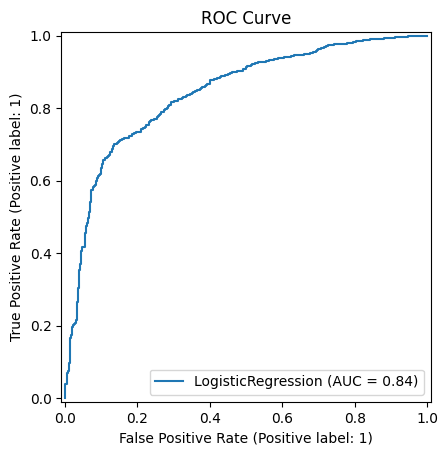

In [33]:
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test)
plt.title("ROC Curve")
plt.show()

In [42]:
df.describe(include='all')

,patient_id,admission_date,age,comorbidities_count,length_of_stay,medications_count,followup_visits_last_year,prev_readmissions,readmission_risk_score,label,...,Binary_Stroke,Binary_Interventional,Binary_Medical,Binary_Surgical,Binary_Medicare,Binary_Private,Binary_Uninsured,Binary_Home Health,Binary_Rehab,Binary_Skilled Nursing
count,8000,8000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,...,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
unique,8000,1092,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,P00001,21-04-2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,57.411625,4.318500,7.789125,7.475750,3.638125,1.57250,0.776937,0.772875,...,0.110375,0.207875,0.448500,0.24850,0.317750,0.381500,0.101000,0.758125,0.006250,0.196000
std,NaN,NaN,16.724388,1.358046,1.930252,2.287917,1.630415,0.89196,0.219885,0.419000,...,0.313376,0.405812,0.497372,0.43217,0.465631,0.485785,0.301348,0.428246,0.078814,0.396993
min,NaN,NaN,18.000000,1.000000,3.000000,2.000000,0.000000,0.00000,0.070000,0.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,46.000000,3.000000,6.000000,6.000000,2.000000,1.00000,0.630000,1.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,NaN,NaN,57.000000,4.000000,8.000000,8.000000,4.000000,1.00000,0.860000,1.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,NaN,NaN,69.000000,5.000000,9.000000,9.000000,4.000000,2.00000,0.970000,1.000000,...,0.000000,0.000000,1.000000,0.00000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000


In [34]:
import lightgbm as lgb

In [35]:
from lightgbm import LGBMClassifier, LGBMRegressor

In [36]:
from lightgbm import LGBMClassifier, LGBMRegressor
model = lgb.LGBMClassifier()
model.fit(X_train_scaled, y_train)

[LightGBM] [Info] Number of positive: 4934, number of negative: 1466
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004376 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 557
[LightGBM] [Info] Number of data points in the train set: 6400, number of used features: 35
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.770938 -> initscore=1.213612
[LightGBM] [Info] Start training from score 1.213612


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [49]:
print(f"Accuracy: {model.score(X_test_scaled, y_test)}")

Accuracy: 0.81125


C:\Users\Ravi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
